 # klassische Load-Balancing-Problem in Distributed Hash Tables (DHTs).
 
 Wenn man Knoten einfach zufällig auf den Ring wirft (z. B. durch das Hashen ihrer IP-Adresse), führt die mathematische Varianz im Worst Case tatsächlich zu einer extremen Ungleichverteilung (Clustering). Ein Knoten ist dann plötzlich für einen riesigen Abschnitt des Rings zuständig und wird mit Daten überflutet, während sein Nachbar fast leer ausgeht.Um dieses Problem zu lösen und eine Gleichverteilung (bzw. eine faire Lastverteilung) zu garantieren, nutzen Systeme wie Chord, Amazon Dynamo oder Kademlia vor allem drei etablierte Strategien:

 * Virtuelle Knoten
 * Intervallhalbierung
 * Gute Hashfunktion (Avalanche Effekt)


In [1]:
import hashlib
from dataclasses import dataclass, field


# Größe des Identifier-Rings: IDs liegen im Bereich [0, 2**M - 1].
# Klein gewählt, damit man den Ring leicht überblicken kann.
M = 6
RING_SIZE = 2**M


def hash_id(key: str) -> int:
    """Bildet einen beliebigen String stabil auf eine Ring-Position ab."""
    digest = hashlib.sha1(key.encode("utf-8")).hexdigest()
    return int(digest, 16) % RING_SIZE

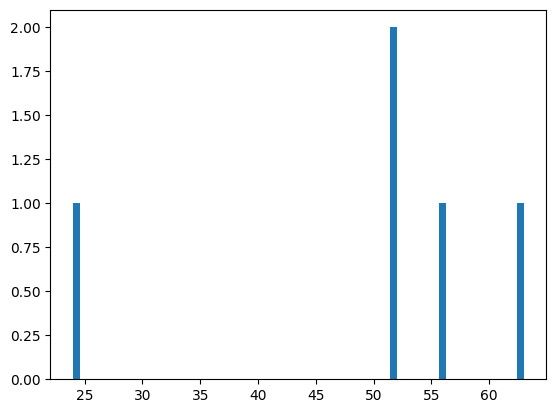

/home/micmink/repos/statistics/venv/lib/python3.10/site-packages/numpy/_core/_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/micmink/repos/statistics/venv/lib/python3.10/site-packages/numpy/_core/_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/micmink/repos/statistics/venv/lib/python3.10/site-packages/numpy/_core/_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/micmink/repos/statistics/venv/lib/python3.10/site-packages/numpy/_core/_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/micmink/repos/statistics/venv/lib/python3.10/site-packages/numpy/_core/_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/h

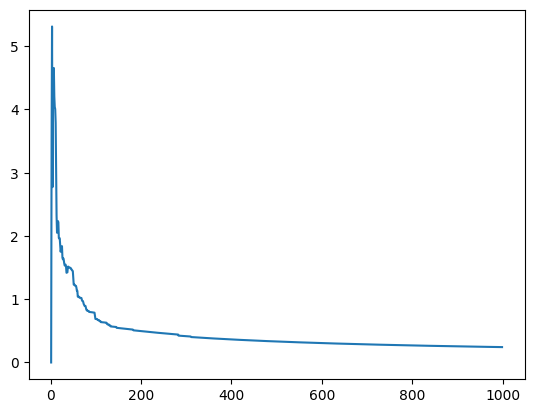

In [2]:
# random string generator

import random
import string
import numpy as np

# Definition der erlaubten Zeichen (Groß-/Kleinbuchstaben + Zahlen)
zeichenpool = string.ascii_letters + string.digits

# 4 zufällige Zeichen auswählen und zusammenfügen
str_list = []
metric_list = []
for _ in range(1000):
    zufaelliger_string = ''.join(random.choices(zeichenpool, k=4))
    str_list.append(zufaelliger_string)

    hash_ids = [hash_id(s) for s in str_list]
   
    # metric
    metric_list.append(np.std(np.abs(np.diff(np.sort(hash_ids)))))

# check if hash keys are uniformly distributed
import matplotlib.pyplot as plt

plt.plot(metric_list)
plt.show()




